# LinkedIn engagement tracker — Visualizing the Unseen campaign

Tests the distribution-throttle hypothesis from `CAMPAIGN.md`'s Distribution note using the account's real `AggregateAnalytics` export (whole-profile, trailing 365 days), not manual screenshot counts.

**Data source:** newest `AggregateAnalytics_*.xlsx` found under `~/coding/` (glob picks the latest by mtime — drop a new export there and re-run to update). Sheets used: `DISCOVERY` (year totals, for a self-check), `ENGAGEMENT` (daily impressions/engagements, whole account), `FOLLOWERS` (daily new-follower counts), `TOP POSTS` (per-post ranking, to check whether any campaign post cracked the account's own top 50).

**Known limits:** this is whole-account daily totals, not per-post — other, unrelated posts (job updates, etc.) also contribute to each day's number. Exact post dates are only confirmed for Day 1/2/3 and the `dc_grid_queue` piece; 6 more campaign posts went out between roughly Aug 12-25 with dates Simon declined to log, shown only as a shaded window, not individual markers.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

xlsx_path = max(glob.glob(os.path.expanduser('~/coding/AggregateAnalytics_*.xlsx')), key=os.path.getmtime)
print('Using export:', xlsx_path)
wb = openpyxl.load_workbook(xlsx_path, data_only=True)

def sheet_rows(name):
    return list(wb[name].iter_rows(values_only=True))

eng_rows = sheet_rows('ENGAGEMENT')[1:]
engagement = pd.DataFrame(eng_rows, columns=['date', 'impressions', 'engagements'])
engagement['date'] = pd.to_datetime(engagement['date'])
engagement['impressions'] = engagement['impressions'].astype(int)
engagement['engagements'] = engagement['engagements'].astype(int)
engagement = engagement.sort_values('date').reset_index(drop=True)

fol_rows = sheet_rows('FOLLOWERS')
fol_data = [r for r in fol_rows if r[0] not in (None, 'Date') and 'Total followers' not in str(r[0])]
followers = pd.DataFrame(fol_data, columns=['date', 'new_followers'])
followers['date'] = pd.to_datetime(followers['date'])
followers['new_followers'] = followers['new_followers'].astype(int)
followers = followers.sort_values('date').reset_index(drop=True)

disc_rows = sheet_rows('DISCOVERY')
disc = {r[0]: r[1] for r in disc_rows if r[0]}
total_impressions_reported = int(disc['Impressions'])

Using export: /home/simonhans/coding/AggregateAnalytics_Simon Hans Edasi_2025-08-28_2026-08-27.xlsx


/home/simonhans/anaconda3/lib/python3.7/site-packages/openpyxl/styles/stylesheet.py:214: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [2]:
assert engagement['date'].min() == pd.Timestamp('2025-08-28'), 'unexpected start date'
assert engagement['date'].max() == pd.Timestamp('2026-08-27'), 'unexpected end date'
assert engagement['date'].is_monotonic_increasing, 'dates out of order'
assert (engagement['date'].diff().dropna() == pd.Timedelta(days=1)).all(), 'gap in daily series'
daily_sum = int(engagement['impressions'].sum())
assert daily_sum == total_impressions_reported, f'daily sum {daily_sum} != DISCOVERY total {total_impressions_reported}'
print(f'Self-check OK: {len(engagement)} consecutive days, {daily_sum} total impressions matches DISCOVERY sheet')

Self-check OK: 365 consecutive days, 24022 total impressions matches DISCOVERY sheet


In [3]:
known_posts = {
    '2026-08-09': 'Day 1: Ode to Joy landscape',
    '2026-08-10': 'Day 2: Transit gap',
    '2026-08-11': 'Day 3: Benford alphabet (01_bounds)',
    '2026-08-26': 'DC grid queue (Texas/ERCOT)',
}
# 6 more campaign posts went out between roughly 08-12 and 08-25 (old Day 4/5/6/7/12/13 labels);
# Simon declined to log exact dates, so they show only as a shaded window below, not markers.
unlogged_window = ('2026-08-12', '2026-08-25')

def window_mean(df, col, start=None, end=None):
    d = df
    if start is not None:
        d = d[d['date'] >= pd.Timestamp(start)]
    if end is not None:
        d = d[d['date'] <= pd.Timestamp(end)]
    return d[col].mean(), len(d)

pre_mean, pre_n = window_mean(engagement, 'impressions', end='2026-08-08')
daily_mean, daily_n = window_mean(engagement, 'impressions', '2026-08-09', '2026-08-14')
early_mean, early_n = window_mean(engagement, 'impressions', '2026-08-15', '2026-08-20')
recent_mean, recent_n = window_mean(engagement, 'impressions', '2026-08-21', '2026-08-27')

print(f'Pre-campaign baseline        (n={pre_n:>2} days, thru Aug 8):   {pre_mean:6.1f} impressions/day')
print(f'Daily-cadence phase          (n={daily_n:>2} days, Aug 9-14):   {daily_mean:6.1f} impressions/day')
print(f'Reduced cadence, early       (n={early_n:>2} days, Aug 15-20):  {early_mean:6.1f} impressions/day')
print(f'Reduced cadence, most recent (n={recent_n:>2} days, Aug 21-27): {recent_mean:6.1f} impressions/day')

Pre-campaign baseline        (n=346 days, thru Aug 8):     59.4 impressions/day
Daily-cadence phase          (n= 6 days, Aug 9-14):    196.7 impressions/day
Reduced cadence, early       (n= 6 days, Aug 15-20):   124.3 impressions/day
Reduced cadence, most recent (n= 7 days, Aug 21-27):  221.3 impressions/day


In [4]:
def window_sum(df, col, start=None, end=None):
    d = df
    if start is not None:
        d = d[d['date'] >= pd.Timestamp(start)]
    if end is not None:
        d = d[d['date'] <= pd.Timestamp(end)]
    return int(d[col].sum())

pre_sum = window_sum(followers, 'new_followers', end='2026-08-08')
daily_sum_f = window_sum(followers, 'new_followers', start='2026-08-09', end='2026-08-14')
early_sum_f = window_sum(followers, 'new_followers', start='2026-08-15', end='2026-08-20')
recent_sum_f = window_sum(followers, 'new_followers', start='2026-08-21', end='2026-08-27')

print('New followers gained, same windows:')
print(f'  pre-campaign (thru Aug 8):        {pre_sum}')
print(f'  daily-cadence (Aug 9-14):          {daily_sum_f}')
print(f'  reduced cadence, early (Aug 15-20): {early_sum_f}')
print(f'  reduced cadence, recent (Aug 21-27): {recent_sum_f}')

New followers gained, same windows:
  pre-campaign (thru Aug 8):        50
  daily-cadence (Aug 9-14):          1
  reduced cadence, early (Aug 15-20): 8
  reduced cadence, recent (Aug 21-27): 2


In [5]:
tp_rows = sheet_rows('TOP POSTS')
data_rows = tp_rows[3:]
top_by_engagement = []
top_by_impressions = []
for r in data_rows:
    if r[0]:
        top_by_engagement.append({'url': r[0], 'date': r[1], 'engagements': int(r[2])})
    if len(r) > 4 and r[4]:
        top_by_impressions.append({'url': r[4], 'date': r[5], 'impressions': int(r[6])})

campaign_start = pd.Timestamp('2026-08-09')

def in_campaign(datestr):
    try:
        return pd.Timestamp(datestr) >= campaign_start
    except Exception:
        return False

hits_eng = [p for p in top_by_engagement if in_campaign(p['date'])]
hits_imp = [p for p in top_by_impressions if in_campaign(p['date'])]
n_hits_eng = len(hits_eng)
n_hits_imp = len(hits_imp)
print(f'Campaign-window posts in account top-50 by engagement: {n_hits_eng}')
for p in hits_eng:
    print(' ', p)
print(f'Campaign-window posts in account top-50 by impressions: {n_hits_imp}')
for p in hits_imp:
    print(' ', p)

Campaign-window posts in account top-50 by engagement: 12
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_day-12-of-visualizing-the-unseen-until-i-ugcPost-7496256379775590400-ysHL', 'date': '8/20/2026', 'engagements': 13}
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_day-4-of-visualizing-the-unseen-until-im-ugcPost-7493299684128542720-C0d9', 'date': '8/12/2026', 'engagements': 5}
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_day-15-of-visualizing-the-unseen-until-i-ugcPost-7497652049518448641-FhgE', 'date': '8/24/2026', 'engagements': 4}
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_grapeexpectations-share-7496568551823126528-9VgF', 'date': '8/21/2026', 'engagements': 3}
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_day-2-of-visualizing-the-unseen-what-is-ugcPost-7492584130673524736-e_hq', 'date': '8/10/2026', 'engagements': 3}
  {'url': 'https://www.linkedin.com/posts/simon-hans-edasi_visualizing-the-unseen-a-toddlers-lite

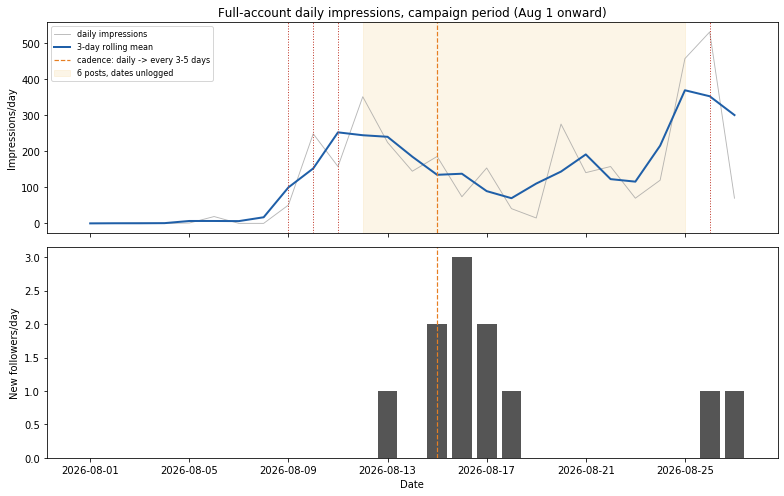

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

plot_start = pd.Timestamp('2026-08-01')
eng_window = engagement[engagement['date'] >= plot_start]
fol_window = followers[followers['date'] >= plot_start]

ax = axes[0]
ax.plot(eng_window['date'], eng_window['impressions'], color='#999999', lw=0.9, alpha=0.7, label='daily impressions')
roll = eng_window['impressions'].rolling(3, center=True, min_periods=1).mean()
ax.plot(eng_window['date'], roll, color='#1f5fa8', lw=2, label='3-day rolling mean')
ax.axvspan(pd.Timestamp(unlogged_window[0]), pd.Timestamp(unlogged_window[1]), color='#f0c060', alpha=0.15, label='6 posts, dates unlogged')
for d in known_posts:
    ax.axvline(pd.Timestamp(d), color='#c0392b', ls=':', lw=1)
ax.axvline(pd.Timestamp('2026-08-15'), color='#e67e22', ls='--', lw=1.2, label='cadence: daily -> every 3-5 days')
ax.set_ylabel('Impressions/day')
ax.set_title('Full-account daily impressions, campaign period (Aug 1 onward)')
ax.legend(fontsize=8, loc='upper left')

ax2 = axes[1]
ax2.bar(fol_window['date'], fol_window['new_followers'], color='#555555', width=0.8)
ax2.axvline(pd.Timestamp('2026-08-15'), color='#e67e22', ls='--', lw=1.2)
ax2.set_ylabel('New followers/day')
ax2.set_xlabel('Date')

plt.tight_layout()
plt.savefig('linkedin_engagement_tracker.png', dpi=150)
plt.show()

In [7]:
ratio_recent_vs_pre = recent_mean / pre_mean if pre_mean else float('nan')
ratio_recent_vs_daily = recent_mean / daily_mean if daily_mean else float('nan')
ratio_early_vs_daily = early_mean / daily_mean if daily_mean else float('nan')

print('Verdict:')
print(f'  Daily-cadence week averaged {daily_mean:.1f} impressions/day account-wide.')
print(f'  Immediately after cutting cadence, that fell to {early_mean:.1f}/day ({ratio_early_vs_daily:.2f}x).')
print(f'  Most recent week is {recent_mean:.1f}/day ({ratio_recent_vs_daily:.2f}x the daily-cadence week, {ratio_recent_vs_pre:.2f}x the pre-campaign baseline).')
print('  Caveat: whole-account daily impressions, not per-post -- no Visualizing the Unseen post')
print('  appears in the account-level top-50 by engagement or impressions (see cross-check above), so')
print('  individual-post reach cannot be isolated from this export -- this only tests the account-level')
print('  throttle hypothesis, not per-post decay curves.')

Verdict:
  Daily-cadence week averaged 196.7 impressions/day account-wide.
  Immediately after cutting cadence, that fell to 124.3/day (0.63x).
  Most recent week is 221.3/day (1.13x the daily-cadence week, 3.73x the pre-campaign baseline).
  Caveat: whole-account daily impressions, not per-post -- no Visualizing the Unseen post
  appears in the account-level top-50 by engagement or impressions (see cross-check above), so
  individual-post reach cannot be isolated from this export -- this only tests the account-level
  throttle hypothesis, not per-post decay curves.
